# 00 · Quickstart

An SO-101 arm in a simulated world: create it, read it, move it, watch it. Five minutes.

![observe, act, render](media/00/loop.svg)

## Install

```bash
git clone https://github.com/strands-labs/robots && cd robots && git checkout dev
uv venv -p 3.12 && source .venv/bin/activate
uv pip install -e ".[mujoco]"
```

That is everything this notebook needs. Agents, recording and policies need more extras; their notebooks say which.

In [1]:
from strands_robots import Robot

arm = Robot("so101")
arm

Robot('so101', id='so101', mujoco, dof=6)

No world was given, so the arm joined `Simulation.default()`, a headless MuJoCo world created for it.

In [2]:
arm.sim

Simulation('mujoco', physics='native', robots=['so101'], t=0.000)

`observe()` reads the body: joint positions in radians, the base pose, and images from cameras attached to it.

In [3]:
obs = arm.observe()
print("t =", obs.t)
print({k: round(v, 3) for k, v in obs.joints.as_dict().items()})

t = 0.0
{'shoulder_pan': 0.0, 'shoulder_lift': 0.0, 'elbow_flex': 0.0, 'wrist_flex': 0.0, 'wrist_roll': 0.0, 'gripper': 0.0}


`act()` writes joint targets and advances the world one control step (20 ms). A joint you leave out is re-targeted to where it is now, so gravity pulls it a little each step (01 shows it).

In [4]:
obs = arm.act({"shoulder_pan": 0.5})
print(f"t = {obs.t:.2f} s, shoulder_pan = {obs['shoulder_pan']:.3f} rad")

t = 0.02 s, shoulder_pan = 0.015 rad


One step only moves part of the way. `seconds=` ramps to the target and returns the pose reached.

In [5]:
obs = arm.act({"shoulder_pan": 0.5, "elbow_flex": 0.6}, seconds=1.0)
print(f"t = {obs.t:.2f} s, shoulder_pan = {obs['shoulder_pan']:.3f}, elbow_flex = {obs['elbow_flex']:.3f}")

t = 1.04 s, shoulder_pan = 0.503, elbow_flex = 0.623


A camera, and one frame from it.

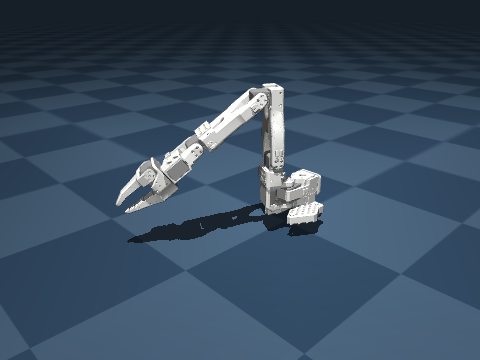

In [6]:
from PIL import Image

arm.sim.camera("front", position=[0.5, -0.6, 0.42], target=[-0.08, -0.05, 0.08], size=(480, 360))
Image.fromarray(arm.sim.render("front"))

A wave: 90 control steps, one frame every second step.

In [7]:
import math

frames = []
for i in range(90):
    t = i * 0.02
    arm.act({"shoulder_pan": 0.8 * math.sin(3 * t), "elbow_flex": 0.6 + 0.4 * math.sin(5 * t)})
    if i % 2 == 0:
        frames.append(arm.sim.render("front"))
print(len(frames), "frames,", f"{arm.sim.time:.2f} s of sim time")

45 frames, 2.84 s of sim time


![the arm waving](media/00/wave.gif)

In [8]:
from pathlib import Path

media = Path("media/00") if Path("media").is_dir() else Path("notebooks/media/00")
media.mkdir(parents=True, exist_ok=True)
gif = [Image.fromarray(f).resize((360, 270)) for f in frames]
gif[0].save(media / "wave.gif", save_all=True, append_images=gif[1:], duration=40, loop=0)
print(media / "wave.gif", f"{(media / 'wave.gif').stat().st_size / 1e3:.0f} KB")

media/00/wave.gif 1560 KB


## Hand it to an agent

`arm.tool` and `arm.sim.tool` are [Strands](https://strandsagents.com) agent tools generated from the robot and the
world. With `uv pip install -e ".[mujoco,tools]"` and Amazon Bedrock credentials:

```python
from strands import Agent

agent = Agent(tools=[arm.tool, arm.sim.tool])
agent("add a red cube in front of the arm, then point the arm at it")
while True:
    agent(input("> "))
```

[03](03_agent_builds_a_world.ipynb) runs this for real.

## Next

[01](01_robot_and_sim.ipynb): what a robot is, two robots in one world, cameras, and the run loop.